## Tagging IAA

In [2]:
## try to compute multi-label multi-user agreement
from irrCAC.raw import CAC
import pandas as pd
import itertools
from iaa import classify_problem, binarize_multilabel_fleiss

from article_utils.util import read_jsonl
from iaa import categorize_tag
import os

def relative_file(filename):
    return os.path.join('..', 'data/doccano/2025.05.01_llm_explanation_quality_v2025.03.25', filename)


ROUND3_ONLY_TAGS = {'Incomplete', 'Misleading Or Overstated', 'Poor Wording Or Grammar'}



tags_df = read_jsonl(relative_file('processed/explanation_tags.jsonl.gz'))

group_df = tags_df.copy()
group_df = group_df[group_df.project.str['collaborative_annotation'] == True]
group_df = group_df.groupby(['review_id', 'review_round']).agg({'is_committee': 'any'}).reset_index()

tags_df = tags_df.merge(group_df, how='left')
tags_df['response_id'] = tags_df.review_id + ' ' + tags_df.response.str['start'].astype(str)
tags_df['tags'] = tags_df.tags.apply(lambda t: set(t))

tags_by_round = {}
for _, row in tags_df.iterrows():
    tags_by_round.setdefault(row['review_round'], set()).update(row['tags'])

COMMON_TAGS = list(tags_by_round.values())
ALL_TAGS = COMMON_TAGS[0].union(*COMMON_TAGS[1:])
COMMON_TAGS = COMMON_TAGS[0].intersection(*COMMON_TAGS[1:])

tags_df['llm_response_start'] = tags_df.response.str['start']

temp_df = tags_df[~tags_df.review_round.str.contains('3')].copy()
temp_df['tags'] = temp_df.tags.apply(lambda tags: tags - ROUND3_ONLY_TAGS)
fk = binarize_multilabel_fleiss(temp_df, 'tags', ['review_id', 'llm_response_start'], 'username')
print('individual tags (exclude round 3):')
print('fk:', fk['est'])
print('fk - pa', fk['est']['pa'])


temp_df = tags_df[~tags_df.review_round.str.contains('3')].copy()
temp_df['tags'] = temp_df.tags.apply(lambda tags: {categorize_tag(t) for t in tags if t not in ROUND3_ONLY_TAGS})
fk = binarize_multilabel_fleiss(temp_df, 'tags', ['review_id', 'llm_response_start'], 'username')
print('\ncategory tags (exlcude round 3):')
print('fk:', fk['est'])
print('fk - pa', fk['est']['pa'])


temp_df =  tags_df[~tags_df.review_round.str.contains('3')].copy()
temp_df['tag_status'] = temp_df.tags.apply(lambda tags: classify_problem(tags - ROUND3_ONLY_TAGS))
temp_df = pd.pivot_table(temp_df, values='tag_status', aggfunc='first', index='response_id', columns='username')
cac = CAC(temp_df, categories=tags_df.tag_status.unique())
fk = cac.fleiss()
print('\nstatus tags (exclude round 3):')
print('fk:', fk['est'])
print('fk - pa', fk['est']['pa'])

tags_df[(tags_df.review_round.str.contains('3')) & (tags_df.tag_status.str.contains('Minor'))][['tags']]


individual tags (exclude round 3):
fk: {'coefficient_value': 0.3109, 'coefficient_name': "Fleiss' kappa", 'confidence_interval': (0.27129, 0.3505), 'p_value': 0.0, 'z': 15.41577, 'se': 0.02017, 'pa': 0.63683, 'pe': 0.47298}
fk - pa 0.63683

category tags (exlcude round 3):
fk: {'coefficient_value': 0.35387, 'coefficient_name': "Fleiss' kappa", 'confidence_interval': (0.30946, 0.39828), 'p_value': 0.0, 'z': 15.64922, 'se': 0.02261, 'pa': 0.67611, 'pe': 0.49872}
fk - pa 0.67611

status tags (exclude round 3):
fk: {'coefficient_value': 0.4134, 'coefficient_name': "Fleiss' kappa", 'confidence_interval': (0.36122, 0.46558), 'p_value': 0.0, 'z': 15.55795, 'se': 0.02657, 'pa': 0.65146, 'pe': 0.40583}
fk - pa 0.65146


,tags
1,"{Helpful, Incomplete}"
11,"{Helpful, Misleading Or Overstated}"
12,"{Helpful, Incomplete}"
16,"{Helpful, Incomplete, Incoherent, Poor Wording..."
18,"{Helpful, Incomplete}"
...,...
613,"{Helpful, Incomplete}"
615,"{Helpful, Incomplete}"
616,"{Helpful, Misleading Or Overstated}"
617,"{Helpful, Incomplete, Incoherent, Poor Wording..."


In [3]:
# now what happends when we group all the error tags together
from sklearn.metrics import cohen_kappa_score


def merge_error_tags(tags):
    tags -= ROUND3_ONLY_TAGS
    error_tags = tags - {'Helpful', 'Untagged', 'Incomplete'}
    if error_tags:
        return tags & {'Helpful'} | {"Error"}
    return tags & {'Helpful'}



binarized_df = tags_df[~tags_df.review_round.str.contains('3')].copy()
binarized_df['tags'] = binarized_df.tags.apply(merge_error_tags)
fk = binarize_multilabel_fleiss(binarized_df, 'tags', ['review_id', 'llm_response_start'], 'username')


print('grouped error tags. helpful and error tags only (exlcude round 3)')
print('fk:', fk['est'])
print('fk - pa', fk['est']['pa'])

### for binary tags?
rows = []

for tag_name in ALL_TAGS - ROUND3_ONLY_TAGS:
    temp_df = tags_df[~tags_df.review_round.str.contains('3')].copy()
    temp_df['tag'] = temp_df.tags.apply(lambda tags: tag_name in tags)
    temp_df = pd.pivot_table(temp_df, values='tag', aggfunc='any', index='response_id', columns='username')
    fk = CAC(temp_df, categories=[True, False]).fleiss()['est']
    rows.append({**{f'fk.{c}': v for c, v in fk.items()}, 'tag': tag_name})

temp_df = pd.DataFrame.from_records(rows)
temp_df


grouped error tags. helpful and error tags only (exlcude round 3)
fk: {'coefficient_value': 0.39833, 'coefficient_name': "Fleiss' kappa", 'confidence_interval': (0.34653, 0.45013), 'p_value': 0.0, 'z': 15.1016, 'se': 0.02638, 'pa': 0.72518, 'pe': 0.54324}
fk - pa 0.72518


,fk.coefficient_value,fk.coefficient_name,fk.confidence_interval,fk.p_value,fk.z,fk.se,fk.pa,fk.pe,tag
0,0.10986,Fleiss' kappa,"(0.01651, 0.20321)",0.021158,2.31119,0.04753,0.87664,0.86141,Extra Information
1,0.17097,Fleiss' kappa,"(0.07213, 0.26982)",0.000726,3.39692,0.05033,0.86215,0.83372,Logic Error
2,0.11008,Fleiss' kappa,"(0.01169, 0.20846)",0.028378,2.19729,0.05010,0.89339,0.88020,Untagged
3,0.41922,Fleiss' kappa,"(0.34132, 0.49711)",0.000000,10.56937,0.03966,0.80380,0.66218,Helpful
4,0.40003,Fleiss' kappa,"(0.31591, 0.48415)",0.000000,9.33889,0.04283,0.82904,0.71505,External Inconsistency
5,0.23988,Fleiss' kappa,"(0.10464, 0.37512)",0.000531,3.48336,0.06886,0.92011,0.89490,"Incoherent, Poor Wording, Or Poor Grammar"
6,0.21299,Fleiss' kappa,"(0.08239, 0.34358)",0.001432,3.20299,0.06650,0.93372,0.91578,Internal Inconsistency




with round 3 data


,tag_name,users,count,coefficient_value,coefficient_name,confidence_interval,p_value,z,se,pa,pe
0,Error,"{creisle, camgrisdale, mbonakdar, kkrysiak, ep...",605,0.43965,Fleiss' kappa,"(0.38878, 0.49052)",0.000000e+00,16.97318,0.02590,0.73780,0.53207
1,External Inconsistency,"{creisle, camgrisdale, mbonakdar, kkrysiak, ep...",605,0.46239,Fleiss' kappa,"(0.40167, 0.52311)",0.000000e+00,14.95554,0.03092,0.82970,0.68322
2,Extra Information,"{creisle, camgrisdale, mbonakdar, kkrysiak, ep...",605,0.19361,Fleiss' kappa,"(0.12429, 0.26294)",6.094997e-08,5.48473,0.03530,0.89719,0.87251
3,Helpful,"{creisle, camgrisdale, mbonakdar, kkrysiak, ep...",605,0.43061,Fleiss' kappa,"(0.36162, 0.49959)",0.000000e+00,12.25892,0.03513,0.82468,0.69210
4,"Incoherent, Poor Wording, Or Poor Grammar","{creisle, camgrisdale, mbonakdar, kkrysiak, ep...",605,0.27460,Fleiss' kappa,"(0.187, 0.3622)",1.357985e-09,6.15630,0.04461,0.89950,0.86146
5,Incomplete,"{creisle, camgrisdale, epleasance, committee, ...",20,1.00000,Fleiss' kappa,"(0.56787, 1)",6.654284e-06,4.54480,0.22003,1.00000,1.00000
6,Internal Inconsistency,"{creisle, camgrisdale, mbonakdar, kkrysiak, ep...",605,0.36622,Fleiss' kappa,"(0.28982, 0.44261)",0.000000e+00,9.41465,0.03890,0.93835,0.90272
7,Logic Error,"{creisle, camgrisdale, mbonakdar, kkrysiak, ep...",605,0.27035,Fleiss' kappa,"(0.19812, 0.34258)",6.430412e-13,7.35089,0.03678,0.86760,0.81855
8,Misleading Or Overstated,"{creisle, camgrisdale, epleasance, committee, ...",20,1.00000,Fleiss' kappa,"(0.56787, 1)",6.654284e-06,4.54480,0.22003,1.00000,1.00000
9,Untagged,"{creisle, camgrisdale, mbonakdar, kkrysiak, ep...",605,0.20968,Fleiss' kappa,"(0.151, 0.26837)",6.110890e-12,7.01688,0.02988,0.87069,0.83638


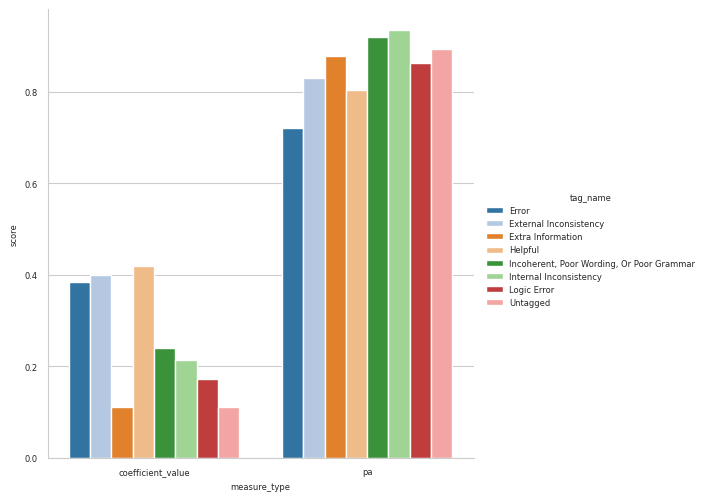

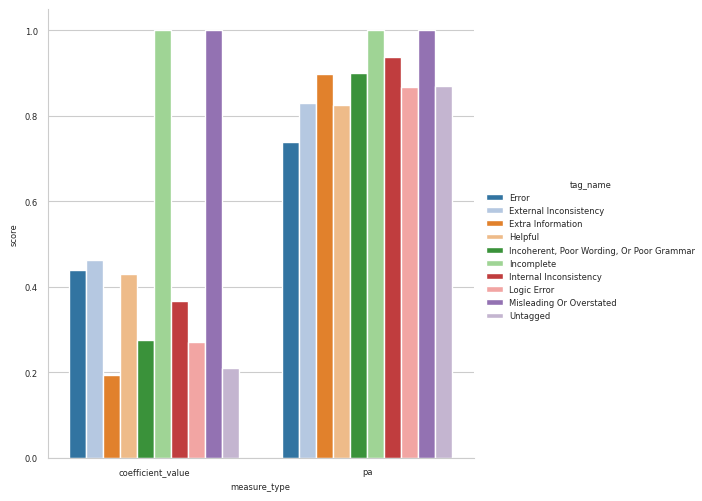

In [4]:
import seaborn as sns
from figutils import add_bar_labels


def mode(items):
    if len(items) < 2:
        return None
    counts = {}
    for item in items:
        counts[item] = counts.get(item, 0) + 1

    counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

    if len(counts) > 1 and counts[0][1] == counts[1][1]:
        return None
    return counts[0][0]


def score_tagging(df, tag_col='tags', target_tags=list(ALL_TAGS) + ['Error'], tags_by_round=None):
    # now let's try computing it per label which seems much simpler
    labels_df = df.copy()

    for tag in target_tags:
        labels_df[tag] = labels_df[tag_col].apply(lambda tags: 'yes' if tag in tags | merge_error_tags(tags) else 'no')
        if tag == 'Error':
            continue
        if not tags_by_round:
            continue
        for review_round in tags_by_round:
            if tag not in tags_by_round[review_round]:
                labels_df.loc[labels_df.review_round == review_round, tag] = None

    labels_df = pd.melt(labels_df, id_vars=['response_id', 'review_id', 'username'], var_name='tag_name', value_name='exists', value_vars=target_tags)

    assignments = {}

    for username, user_tags_df in tags_df.groupby('username'):
        assignments[username] = set(user_tags_df.response_id.unique())

    scores = []
    for tag_name, tag_name_df in labels_df.groupby('tag_name'):
        tag_name_df = tag_name_df[~tag_name_df.exists.isna()]
        counts_df = tag_name_df.groupby(['response_id', 'review_id']).agg({'username': 'unique', 'exists': list}).reset_index().rename(columns={'exists': 'all_exists', 'username': 'users'})
        counts_df['cons_exists'] = counts_df.all_exists.apply(mode).fillna('no majority')
        counts_df['any_exists'] = counts_df.all_exists.apply(lambda ex: 'yes' in ex)
        counts_df = counts_df.drop(columns=['any_exists']).merge(counts_df.groupby('review_id').agg({'any_exists': 'any'}).reset_index())
        counts_df = counts_df[(counts_df.users.str.len() > 1)]

        temp_df = pd.pivot_table(tag_name_df, values=['exists'], aggfunc='first', index=['response_id'], columns='username')

        # percent agreement
        score = {'tag_name': tag_name,  'users': set(itertools.chain.from_iterable(counts_df.users)), 'count': counts_df.response_id.nunique()}

        try:

            fk = CAC(temp_df.dropna(how='all', axis=1), categories=['yes', 'no']).fleiss()
            score.update(**fk['est'])
        except ZeroDivisionError:
            # cannot calc fleiss for any reviews with a single user
            pass
        scores.append(score)


    scores_df = pd.DataFrame.from_records(scores)
    scores_df = scores_df[scores_df['count'] >= 15]  # min 3 reviews
    return scores_df


sns.set_style('whitegrid')

total_responses = tags_df.response_id.nunique()
scores_df = score_tagging(tags_df[~tags_df.review_round.str.contains('3')], tags_by_round=tags_by_round)
fig_df = scores_df.copy()
fig_df = pd.melt(fig_df, id_vars='tag_name', value_name='score', value_vars=['coefficient_value', 'pa'], var_name='measure_type')
sns.catplot(fig_df, x='measure_type', y='score', hue='tag_name', kind='bar', palette='tab20')

print('\n\nwith round 3 data')
scores_df = score_tagging(tags_df, tags_by_round=tags_by_round)
fig_df = scores_df.copy()
fig_df = pd.melt(fig_df, id_vars='tag_name', value_name='score', value_vars=['coefficient_value', 'pa'], var_name='measure_type')
sns.catplot(fig_df, x='measure_type', y='score', hue='tag_name', kind='bar', palette='tab20')

scores_df